# 04 · Markov Networks (Markov Random Fields)

**Covers:** Lab Exercise 4 (5-variable network), Assignment 4 (factorisation proof,
weather stations, image restoration).

### Theory in one cell
- Undirected graph; the joint distribution is a product of **potentials** over **cliques**:
  $$P(x) = \frac1Z\prod_C \phi_C(x_C),\qquad Z = \sum_x \prod_C \phi_C(x_C)\ \text{(partition function)}$$
- Potentials are **not** probabilities (any positive numbers). Energy form: $\phi = e^{-E}$, so $P(x)\propto e^{-E(x)}$ and **MAP = argmin E**.
- **Clique** = fully connected set of nodes; **maximal** = cannot be enlarged.
- **Separation:** A ⊥ C | B if every path from A to C goes through B (simpler than d-separation, no colliders).
- **Ising model** (spins $s_i\in\{-1,+1\}$): $E(s) = -J\sum_{(i,j)} s_i s_j - h\sum_i s_i$ → neighbours prefer equal values.

In [1]:
%pip install -q pgmpy pyagrum networkx matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
warnings.filterwarnings("ignore")                  # hide library deprecation warnings

import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
from itertools import product
from pathlib import Path

import pyagrum as gum                               # used in the lab for Markov networks
from pgmpy.models import DiscreteMarkovNetwork      # pgmpy version of a Markov network
from pgmpy.factors.discrete import DiscreteFactor   # a potential (factor) over some variables
from pgmpy.inference import BeliefPropagation       # exact inference on trees

FIG = Path("figures")
FIG.mkdir(exist_ok=True)

## Exercise 1 · Five binary variables (Lab 4)

Edges: A1–A2, A1–A3, A2–A4, A2–A5, A3–A4, A4–A5. Potentials of the maximal cliques:

$$\phi_C(a_C) = \exp\Big(\beta\sum_{i<j\in C} a_i a_j\Big)$$

**a) Maximal cliques:** {A1,A2}, {A1,A3}, {A3,A4}, {A2,A4,A5}. (A2, A4, A5 form a triangle;
the 4-cycle A1–A2–A4–A3 has no chord, so there is no bigger clique.)

pyAgrum variables: ['A1', 'A2', 'A3', 'A4', 'A5']
Maximal cliques: [['A2', 'A4', 'A5'], ['A1', 'A2'], ['A3', 'A4'], ['A1', 'A3']]


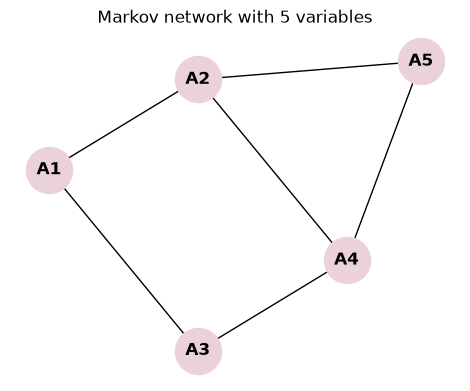

In [ ]:
edges = [("A1", "A2"), ("A1", "A3"), ("A2", "A4"), ("A2", "A5"), ("A3", "A4"), ("A4", "A5")]
names = ["A1", "A2", "A3", "A4", "A5"]

# Graph in pyAgrum. fastMRF takes a string "X--Y; ..." (it fills random factors, replaced below).
# In a notebook with IPython you can draw it with:  import pyagrum.lib.notebook as gnb; gnb.showMRF(mn)
mn = gum.fastMRF("; ".join(f"{u}--{v}" for u, v in edges))
print("pyAgrum variables:", sorted(mn.names()))

# Maximal cliques with networkx
G = nx.Graph(edges)
cliques = [sorted(c) for c in nx.find_cliques(G)] #Encuentra los maximos cliques
print("Maximal cliques:", cliques)

plt.figure(figsize=(4.5, 3.5))
nx.draw(G, {"A1": (0, 1), "A2": (1, 1.5), "A3": (1, 0), "A4": (2, 0.5), "A5": (2.5, 1.6)},
        with_labels=True, node_size=1100, node_color="#ead1dc", font_weight="bold")
plt.title("Markov network with 5 variables")
plt.savefig(FIG / "04_five_variables.png", dpi=150, bbox_inches="tight")
plt.show()

**b) Joint distribution.** Every edge belongs to exactly one maximal clique, so the product
of the clique potentials is

$$P(a) = \frac1Z \exp\Big(\beta \sum_{(i,j)\in E} a_i a_j\Big).$$

With β > 0 the more edges with both ends equal to 1, the better ⇒ the maximum is **(1,1,1,1,1)**
with probability $e^{6\beta}/Z$. We enumerate the $2^5 = 32$ configurations.

In [4]:
beta = 0.5
idx = {n: i for i, n in enumerate(names)}            # variable name -> column index

configs = np.array(list(product([0, 1], repeat=5)))  # 32 rows, one per configuration
# unnormalised score = product of potentials = exp(beta * sum over edges of a_i * a_j)
score = np.exp(beta * sum(configs[:, idx[u]] * configs[:, idx[v]] for u, v in edges))
Z = score.sum()                                      # partition function
P = score / Z                                        # normalised joint probability

print(f"beta = {beta},  Z = {Z:.4f}")
print("Five most probable configurations:")
for k in np.argsort(-P)[:5]:
    print("  ", dict(zip(names, configs[k].tolist())), f"P = {P[k]:.4f}")

beta = 0.5,  Z = 96.8460
Five most probable configurations:
   {'A1': 1, 'A2': 1, 'A3': 1, 'A4': 1, 'A5': 1} P = 0.2074
   {'A1': 0, 'A2': 1, 'A3': 1, 'A4': 1, 'A5': 1} P = 0.0763
   {'A1': 1, 'A2': 1, 'A3': 0, 'A4': 1, 'A5': 1} P = 0.0763
   {'A1': 1, 'A2': 1, 'A3': 1, 'A4': 1, 'A5': 0} P = 0.0763
   {'A1': 1, 'A2': 0, 'A3': 1, 'A4': 1, 'A5': 1} P = 0.0463


In [5]:
# Same model inside pyAgrum, to check a marginal with its inference engine.
for f in list(mn.factors()):          # remove the random factors created by fastMRF
    mn.eraseFactor(f)
for c in cliques:
    t = mn.addFactor(c)               # empty factor over the clique variables
    # fillWith expects the values with the FIRST variable changing fastest -> reverse each tuple
    values = []
    for conf in product([0, 1], repeat=len(c)):
        a = conf[::-1]
        values.append(np.exp(beta * sum(a[i] * a[j] for i in range(len(c)) for j in range(i + 1, len(c)))))
    t.fillWith(values)

ie = gum.ShaferShenoyMRFInference(mn)
ie.makeInference()
print("pyAgrum  P(A1):", ie.posterior("A1"))
print(f"enumeration P(A1=1) = {P[configs[:, 0] == 1].sum():.4f}")

pyAgrum  P(A1): 
  A1               │
0        │1        │
─────────│─────────│
 0.3361  │ 0.6639  │

enumeration P(A1=1) = 0.6639


**c) Ising model.** The potential above only rewards pairs (1,1). To reward **equal**
neighbours (also 0–0) map $a_i\in\{0,1\}$ to spins $s_i = 2a_i-1\in\{-1,+1\}$ and use
$\phi_{ij} = e^{\beta s_i s_j}$ (or equivalently $\phi_{ij} = e^{\beta[a_i = a_j]}$).
Then all-0 and all-1 are the two most probable configurations.

In [6]:
spins = 2 * configs - 1                               # 0 -> -1, 1 -> +1
P_ising = np.exp(beta * sum(spins[:, idx[u]] * spins[:, idx[v]] for u, v in edges))
P_ising /= P_ising.sum()
best = np.flatnonzero(np.isclose(P_ising, P_ising.max()))
print("Ising maxima:", [tuple(configs[k].tolist()) for k in best], f"P = {P_ising.max():.4f}")

Ising maxima: [(0, 0, 0, 0, 0), (1, 1, 1, 1, 1)] P = 0.2620


## Exercise 2 · Factorisation ⇔ conditional independence (Assignment 4, proof)

Graph A – B – C, strictly positive distribution.

**a)** A ⊥ C | B means: once B is known, C gives **no extra information** about A:
$P(a\mid b,c) = P(a\mid b)$.

**b) ⇒** From the definition of conditional probability and A ⊥ C | B:
$$P(a,b,c) = P(b)\,P(a\mid b)\,P(c\mid a,b) = P(b)\,P(a\mid b)\,P(c\mid b).$$
Take $\phi_{AB}(a,b) = P(a\mid b)P(b)$ and $\phi_{BC}(b,c) = P(c\mid b)$, $Z = 1$. Both are > 0.

**c) ⇐** If $P(a,b,c) = \frac1Z\phi_{AB}(a,b)\phi_{BC}(b,c)$, then
$$P(a,c\mid b) = \frac{\phi_{AB}(a,b)\phi_{BC}(b,c)}{\sum_{a',c'}\phi_{AB}(a',b)\phi_{BC}(b,c')}
= \underbrace{\frac{\phi_{AB}(a,b)}{\sum_{a'}\phi_{AB}(a',b)}}_{P(a\mid b)}\cdot
\underbrace{\frac{\phi_{BC}(b,c)}{\sum_{c'}\phi_{BC}(b,c')}}_{P(c\mid b)}$$
so $P(a,c\mid b) = P(a\mid b)P(c\mid b)$, i.e. A ⊥ C | B. ∎

## Exercise 3 · Weather stations on a tree (Assignment 4)

5 stations, edges S1–S2, S1–S3, S2–S4, S2–S5 (4 edges, 5 nodes, connected ⇒ a **tree**, no cycles).
States: Sunny, Rainy, Cloudy. Unary $\phi_i(s) = (0.5, 0.3, 0.2)$; pairwise
$\phi_{ij}(s_i,s_j) = \Psi_{s_i s_j}$ with

$$\Psi = \begin{pmatrix}0.7&0.2&0.1\\0.2&0.6&0.2\\0.1&0.3&0.6\end{pmatrix},\qquad
P(s) = \frac1Z\prod_i\phi_i(s_i)\prod_{(i,j)\in E}\Psi_{s_i s_j}.$$

Neighbours: {'S1': ['S2', 'S3'], 'S2': ['S1', 'S4', 'S5'], 'S3': ['S1'], 'S4': ['S2'], 'S5': ['S2']}
Is it a tree (no cycles)? True


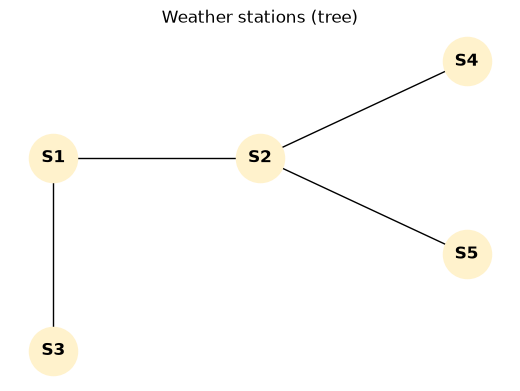

In [7]:
STATES = ["Sunny", "Rainy", "Cloudy"]
stations = ["S1", "S2", "S3", "S4", "S5"]
tree_edges = [("S1", "S2"), ("S1", "S3"), ("S2", "S4"), ("S2", "S5")]
p = np.array([0.5, 0.3, 0.2])
Psi = np.array([[0.7, 0.2, 0.1],
                [0.2, 0.6, 0.2],
                [0.1, 0.3, 0.6]])

# a) neighbours and acyclicity
T = nx.Graph(tree_edges)
print("Neighbours:", {n: sorted(T.neighbors(n)) for n in stations})
print("Is it a tree (no cycles)?", nx.is_tree(T))

plt.figure(figsize=(5, 3.5))
nx.draw(T, {"S1": (0, 1), "S2": (1, 1), "S3": (0, 0), "S4": (2, 1.5), "S5": (2, 0.5)},
        with_labels=True, node_size=1200, node_color="#fff2cc", font_weight="bold")
plt.title("Weather stations (tree)")
plt.savefig(FIG / "04_weather_tree.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
# b) Discrete Markov model in pgmpy.
# DiscreteFactor(variables, cardinalities, values): values in C order -> the FIRST
# variable changes SLOWEST, so Psi.flatten() gives Psi[s_i, s_j] in the right order.
mrf = DiscreteMarkovNetwork(tree_edges)
for n in stations:                                        # unary factors phi_i(s) = p(s)
    mrf.add_factors(DiscreteFactor([n], [3], p, state_names={n: STATES}))
for u, v in tree_edges:                                   # pairwise factors phi_ij = Psi
    mrf.add_factors(DiscreteFactor([u, v], [3, 3], Psi.flatten(), state_names={u: STATES, v: STATES}))
print("Model OK:", mrf.check_model())

Model OK: True


In [9]:
# d) Weather known at S1 (Sunny) and S4 (Rainy): marginal of each unobserved station.
bp = BeliefPropagation(mrf)          # exact on trees
evidence = {"S1": "Sunny", "S4": "Rainy"}
for n in ["S2", "S3", "S5"]:
    q = bp.query([n], evidence=evidence, show_progress=False)
    print(f"P({n} | evidence) = {np.round(q.values, 4)}  -> marginal MAP: {STATES[q.values.argmax()]}")

# e) joint MAP of all unobserved stations together
print("\nJoint MAP:", bp.map_query(["S2", "S3", "S5"], evidence=evidence, show_progress=False))

P(S2 | evidence) = [0.6971 0.2668 0.0361]  -> marginal MAP: Sunny
P(S3 | evidence) = [0.814  0.1395 0.0465]  -> marginal MAP: Sunny
P(S5 | evidence) = [0.6577 0.2598 0.0824]  -> marginal MAP: Sunny

Joint MAP: {'S2': 'Sunny', 'S5': 'Sunny', 'S3': 'Sunny'}


In [10]:
# Check by brute force: enumerate the 3^5 = 243 configurations (feasible for n <= 6)
k = {n: i for i, n in enumerate(stations)}
best, best_w = None, -1
for c in product(range(3), repeat=5):
    if c[k["S1"]] != 0 or c[k["S4"]] != 1:               # keep only configurations matching the evidence
        continue
    w = np.prod([p[s] for s in c]) * np.prod([Psi[c[k[u]], c[k[v]]] for u, v in tree_edges])
    if w > best_w:
        best, best_w = c, w
print("Brute-force joint MAP:", {n: STATES[best[k[n]]] for n in ["S2", "S3", "S5"]})

Brute-force joint MAP: {'S2': 'Sunny', 'S3': 'Sunny', 'S5': 'Sunny'}


**Do the marginal maxima and the joint MAP always coincide? No.** Here they do, but the
marginal MAP maximises each $P(S_i\mid ev)$ separately (summing over the others), while the
joint MAP maximises $P(S_2,S_3,S_5\mid ev)$ at once. A two-variable counter-example:

In [11]:
J = np.array([[0.35, 0.05],      # joint P(X, Y): rows X = 0/1, columns Y = 0/1
              [0.30, 0.30]])
x_marg, y_marg = J.sum(1).argmax(), J.sum(0).argmax()       # maximise each marginal
x_map, y_map = np.unravel_index(J.argmax(), J.shape)        # maximise the joint
print(f"Marginal maxima: (X, Y) = ({x_marg}, {y_marg}) with P = {J[x_marg, y_marg]}")
print(f"Joint MAP:       (X, Y) = ({int(x_map)}, {int(y_map)}) with P = {J.max()}")

Marginal maxima: (X, Y) = (1, 0) with P = 0.3
Joint MAP:       (X, Y) = (0, 0) with P = 0.35


## Exercise 4 · Restoring a binary image (Assignment 4)

5×5 binary image, 4-neighbour grid. Observed noisy image y, unknown clean image x:

$$E(x;y) = \lambda\sum_i (x_i-y_i)^2 + \sum_{(i,j)\in E}(x_i-x_j)^2,\qquad P(x\mid y)\propto e^{-E(x;y)}$$

- **Unary term** (fidelity): $\phi_i(x_i) = e^{-\lambda(x_i-y_i)^2}$ – penalises changing an observed pixel.
- **Pairwise term** (smoothness): $\phi_{ij} = e^{-(x_i-x_j)^2}$ – penalises neighbours with different values.
- **Small λ** ⇒ smoothness dominates (the image gets flattened). **Large λ** ⇒ fidelity dominates ($x^*\approx y$, noise stays).

**ICM (Iterated Conditional Modes):** visit each pixel and set it to the value (0 or 1) with the
lowest *local* energy given its neighbours; repeat until nothing changes. Fast, but it can get
stuck in a **local** minimum. For comparison we also compute the **exact** MAP with dynamic
programming over rows (each row has $2^5 = 32$ states – like Viterbi with rows as states).

In [12]:
rng = np.random.default_rng(5)                 # fixed seed -> reproducible noise

# a) original image: white 3x3 square on black background
x_true = np.zeros((5, 5), dtype=int)
x_true[1:4, 1:4] = 1

# b) flip ~10 % of the pixels (3 of 25)
y = x_true.copy()
flip = rng.choice(25, size=3, replace=False)   # 3 different pixel indices
y.flat[flip] ^= 1                              # XOR with 1 flips 0 <-> 1
print("original:\n", x_true, "\nnoisy:\n", y)


def energy(x, y, lam):
    """E(x; y): lam * (#pixels changed) + (#neighbouring pairs with different values)."""
    return (lam * np.sum((x - y) ** 2)
            + np.sum(np.diff(x, axis=0) ** 2)      # vertical neighbours
            + np.sum(np.diff(x, axis=1) ** 2))     # horizontal neighbours


def icm(y, lam, max_iter=20):
    """Iterated Conditional Modes: greedy pixel-by-pixel energy minimisation."""
    x = y.copy()                                   # start from the observed image
    for _ in range(max_iter):
        changed = False
        for i, j in product(range(5), range(5)):
            # values of the 4 neighbours that exist (borders have fewer)
            neigh = [x[a, b] for a, b in ((i-1, j), (i+1, j), (i, j-1), (i, j+1)) if 0 <= a < 5 and 0 <= b < 5]
            # local energy of setting this pixel to 0 and to 1
            local = [lam * (v - y[i, j]) ** 2 + sum((v - n) ** 2 for n in neigh) for v in (0, 1)]
            best = int(np.argmin(local))
            if best != x[i, j]:
                x[i, j], changed = best, True
        if not changed:                            # converged: no pixel changed in a full sweep
            break
    return x


def exact_map(y, lam):
    """Global minimum of E via dynamic programming over rows (32 possible rows)."""
    rows = np.array(list(product([0, 1], repeat=5)))
    # cost of a row on its own: fidelity + horizontal smoothness inside the row
    row_cost = lambda r: lam * ((rows - y[r]) ** 2).sum(1) + (np.diff(rows, axis=1) ** 2).sum(1)
    # vertical smoothness between every pair of consecutive rows
    between = ((rows[:, None, :] - rows[None, :, :]) ** 2).sum(2)
    cost, back = row_cost(0), []
    for r in range(1, 5):
        total = cost[:, None] + between            # previous best + transition
        back.append(total.argmin(0))               # remember the best previous row
        cost = total.min(0) + row_cost(r)
    path = [int(cost.argmin())]
    for b in reversed(back):                       # backtracking
        path.insert(0, int(b[path[0]]))
    return rows[path]

original:
 [[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]] 
noisy:
 [[1 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [1 1 1 1 1]
 [0 0 0 0 0]]


ICM   lambda = 0.3  energy =  7.40   wrong pixels = 11
ICM   lambda = 1    energy = 15.00   wrong pixels = 0
ICM   lambda = 3    energy = 16.00   wrong pixels = 3


Exact lambda = 0.3  energy =  3.60   wrong pixels = 9


Exact lambda = 1    energy = 12.00   wrong pixels = 9
Exact lambda = 3    energy = 16.00   wrong pixels = 3


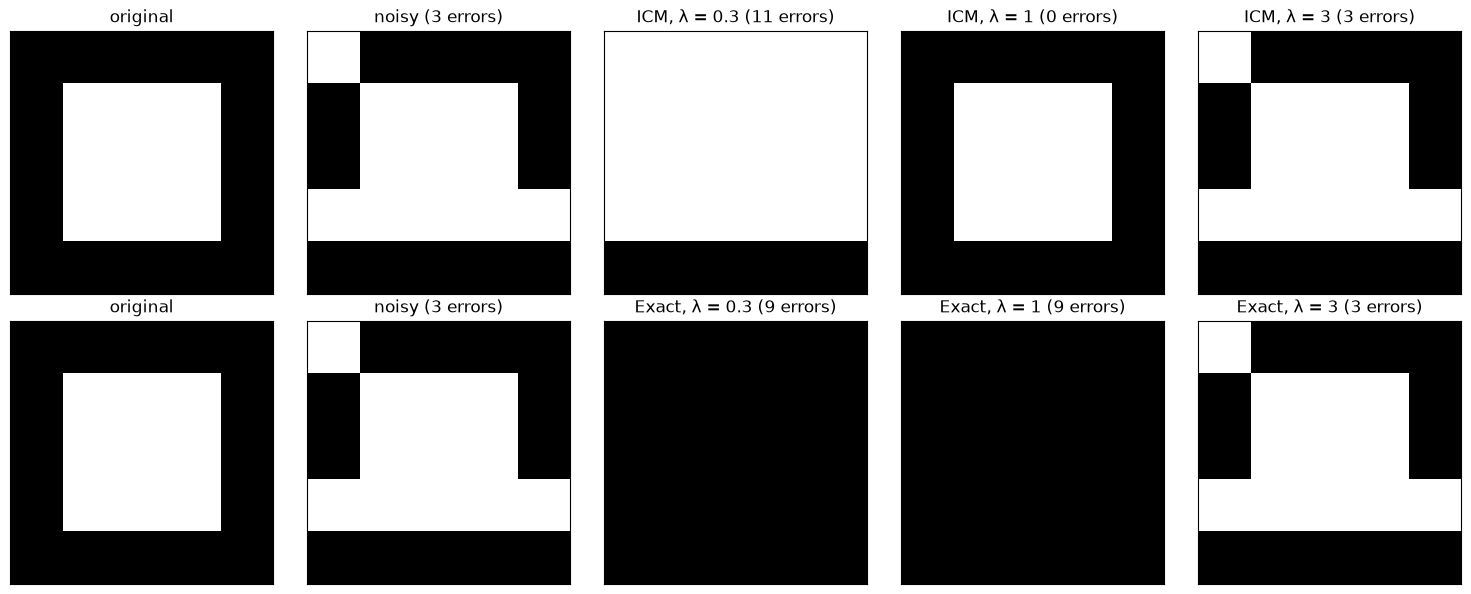

In [13]:
lambdas = [0.3, 1, 3]
fig, axes = plt.subplots(2, 2 + len(lambdas), figsize=(15, 6))
for r, (name, method) in enumerate([("ICM", icm), ("Exact", exact_map)]):
    axes[r, 0].imshow(x_true, cmap="gray", vmin=0, vmax=1); axes[r, 0].set_title("original")
    axes[r, 1].imshow(y, cmap="gray", vmin=0, vmax=1); axes[r, 1].set_title(f"noisy ({(y != x_true).sum()} errors)")
    for c, lam in enumerate(lambdas, start=2):
        x_hat = method(y, lam)
        errors = int((x_hat != x_true).sum())
        print(f"{name:5s} lambda = {lam:<4} energy = {energy(x_hat, y, lam):5.2f}   wrong pixels = {errors}")
        axes[r, c].imshow(x_hat, cmap="gray", vmin=0, vmax=1)
        axes[r, c].set_title(f"{name}, λ = {lam} ({errors} errors)")
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.savefig(FIG / "04_image_restoration.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the results**
- λ = 0.3: smoothness dominates → the exact MAP turns almost everything black (the square is erased).
- λ = 3: fidelity dominates → $x^* = y$, the 3 noisy pixels stay.
- λ = 1: ICM (a *local* minimum) recovers the perfect image (E = 15), but the *global* MAP has
  lower energy (E = 12, all black): on such a tiny image the 12 boundary edges of the square cost
  more than erasing its 9 pixels. **The MAP minimises the energy, not the error w.r.t. the original**
  – choosing λ (and the model) matters.

### Key takeaways
- Factors are not probabilities: normalise with Z (`q.normalize()` if a pgmpy query on an MRF is unnormalised).
- `DiscreteFactor` values: first variable changes slowest. pyAgrum `fillWith`: first variable changes fastest.
- For small models, **always check with brute-force enumeration**.